# Data 200: Data Systems for Data Analytics (Fall 2025)

# Project 2: Relational Model

<font color='red'>**Due Date and Time:** 11:59pm, 12/5/2025 </font>
---
Enter your name in the markdown cell below.

# Name: Grace Ngo

In [4]:
## RUN THIS CELL TO GET THE RIGHT FORMATTING AND TO LOAD NumPy
import requests
import numpy as np
from IPython.core.display import HTML
styles = requests.get("https://raw.githubusercontent.com/Harvard-IACS/2018-CS109A/master/content/styles/cs109.css").text
HTML(styles)

# Tasks
Write functions that perform relational analysis on an SQLite IMDb database that include:
- Use SQL joins across multiple tables
- Perform aggregation and grouping in SQL
- Functions accept at least two parameters
- Produce plots for visualization

# Exercises (Part 2): Data Analyzing

**Run the code cell below to set up the environment**

In [5]:
import sqlite3
import pandas as pd
import sqlalchemy as sa
import os.path
import matplotlib.pyplot as plt
import seaborn as sns
from textwrap import fill

Create and **print** a connection string (called `cstring`) that can be used to connect to the `imdb` database using sqlite.

In [6]:
cstring = r"imdb.db"
print(cstring)

imdb.db


**Run the code cell below to establish the connec|tion using newly defined connection string `cstring`.**

In [7]:
connection = sqlite3.connect(cstring)

**Genre Runtime vs Rating Scatter With Trendline**

In [8]:
def runtime_vs_rating_by_genre(connection, genres, min_votes = 200, min_runtime = 40, max_runtime = 200):
    fig, axes = plt.subplots(2, 4, figsize = (20,10))
    axes = axes.flatten()

    for idx, genre in enumerate(genres):
        sql = """
        SELECT
            r.rating, t.runtime_minutes AS runtime,
            ROUND(t.runtime_minutes / 10) * 10 AS runtime_bin
        FROM titles AS t
        JOIN ratings AS r 
        USING (title_id)
        WHERE t.genres LIKE '%' || :genre || '%'
          AND t.type = 'movie'
          AND t.runtime_minutes BETWEEN :min_rt AND :max_rt
          AND r.votes >= :min_votes
          AND r.rating IS NOT NULL
          AND t.runtime_minutes IS NOT NULL
        GROUP BY runtime_bin
        ORDER BY runtime_bin;
        """
        df = pd.read_sql_query(sql, connection, params = {"genre": genre, "min_rt": min_runtime, "max_rt": max_runtime, "min_votes": min_votes})

        ax = axes[idx]
        if df.empty:
            ax.set_title(f"{genre} (No data)")
            continue

        ax.plot(df["runtime_bin"], df["rating"], color = "red", linewidth = 2)
        ax.scatter(df["runtime"], df["rating"], alpha = 0.35)
 
        ax.set_title(f"{genre}", fontsize = 15, fontweight = "bold")
        ax.set_xlabel("Runtime (minutes)", fontsize = 10)
        ax.set_ylabel("IMDb Rating", fontsize = 10)
        
        ax.set_xlim(40, 200)
        ax.set_ylim(3.5, 9.5)

    plt.suptitle("Runtime vs IMDb Rating With Trendlines Across Genres", fontsize = 22, fontweight = "bold", y = 0.95)
    plt.tight_layout(rect = [0, 0, 1, 0.95])
    plt.show()

    return

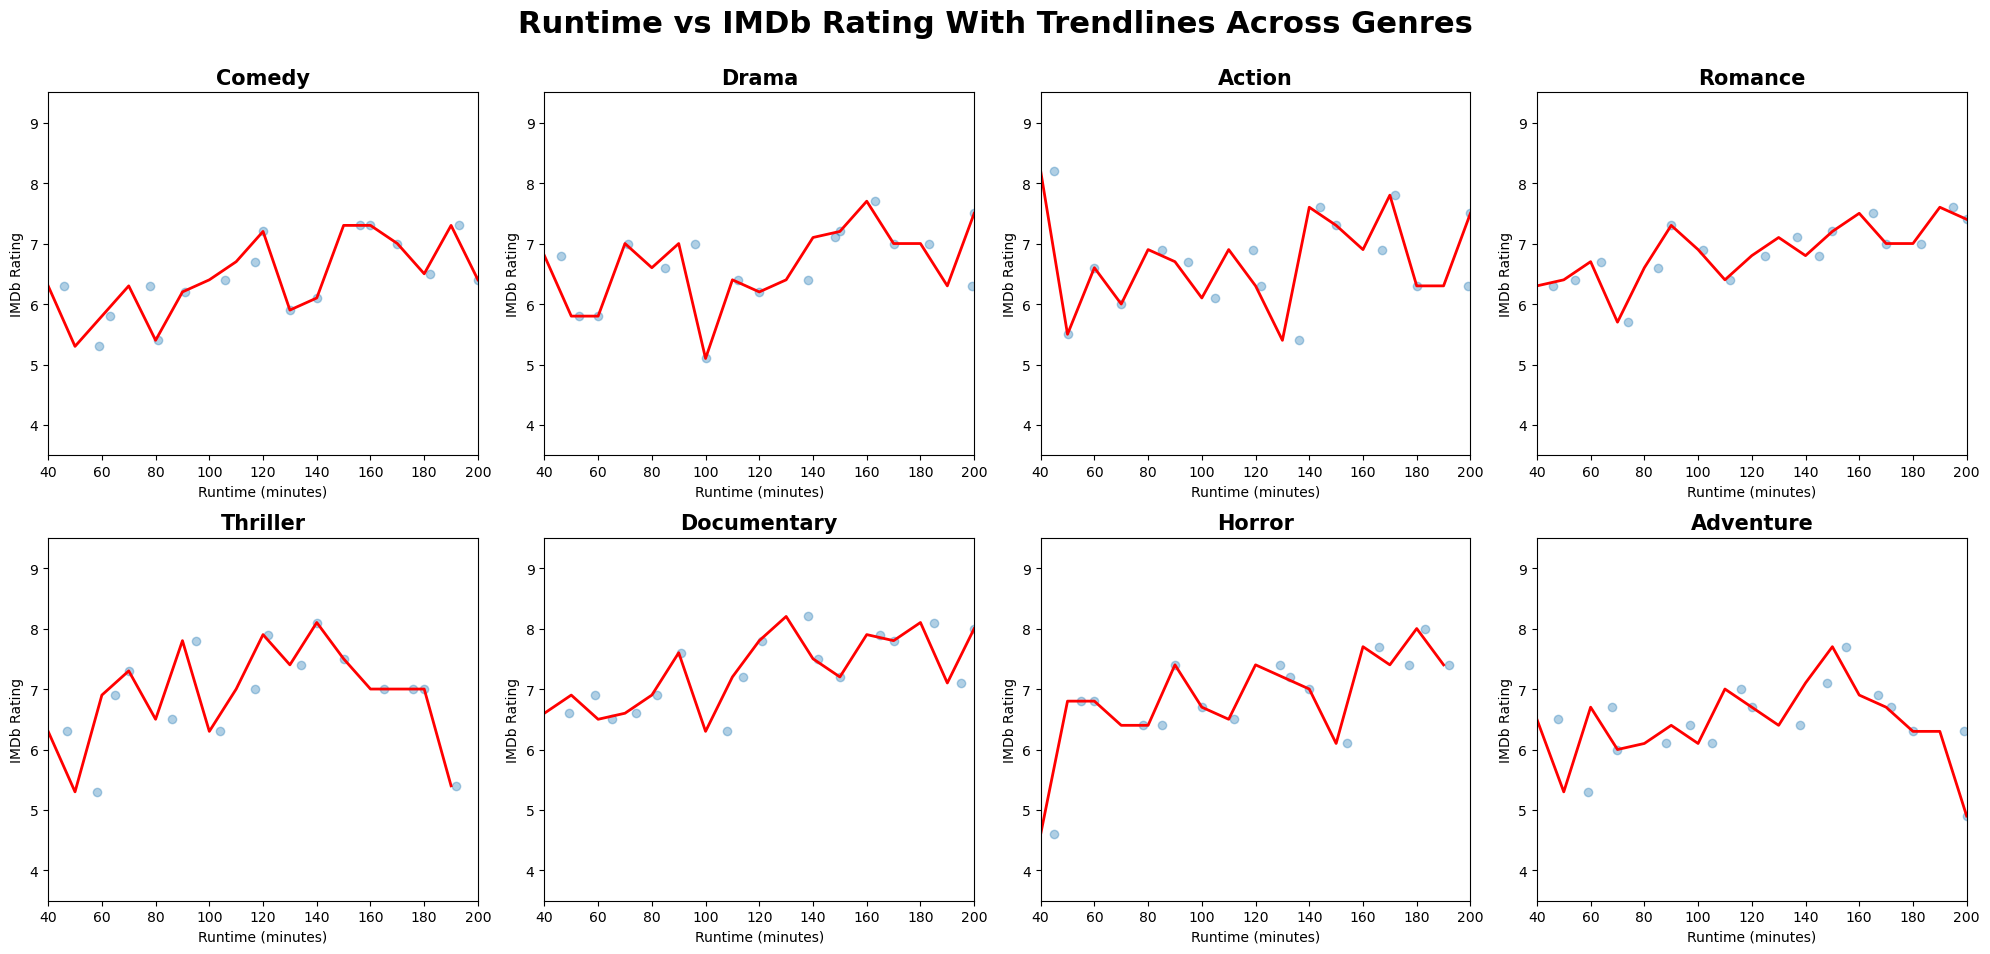

In [9]:
runtime_vs_rating_by_genre(connection, ['Comedy','Drama','Action', 'Romance', 'Thriller', 'Documentary', 'Horror', 'Adventure'], min_votes = 200, min_runtime = 40, max_runtime = 200)

**Genre Popularity Over Decades (Heatmap)**

In [10]:
def genre_popularity_heatmap(connection, genres, decade_start = 1920, decade_end = 2020):
    sql = """
    SELECT 
        t.genres,
        (t.premiered / 10) * 10 AS decade
    FROM titles AS t
    WHERE t.premiered BETWEEN :start AND :end
      AND t.type = 'movie';
    """

    df = pd.read_sql_query(sql, connection, params = {"start": decade_start, "end": decade_end})

# Expand mixed genres
    rows = []
    for _, row in df.iterrows():
        for g in genres:
            if g in str(row["genres"]):
                rows.append({"genre": g, "decade": row["decade"]})

    df_clean = pd.DataFrame(rows)

# Group inside Python only for pivot shape
    pivot = df_clean.pivot_table(index = "genre", columns = "decade", aggfunc = "size", fill_value = 0)

    plt.figure(figsize = (14, 6))
    sns.heatmap(pivot, cmap = "Blues", annot = True, fmt = "d")
    plt.title("Film Production by Genre & Decade", fontsize = 16, fontweight = "bold")
    plt.xlabel("Decade")
    plt.ylabel("Genre")
    plt.show()

    return pivot

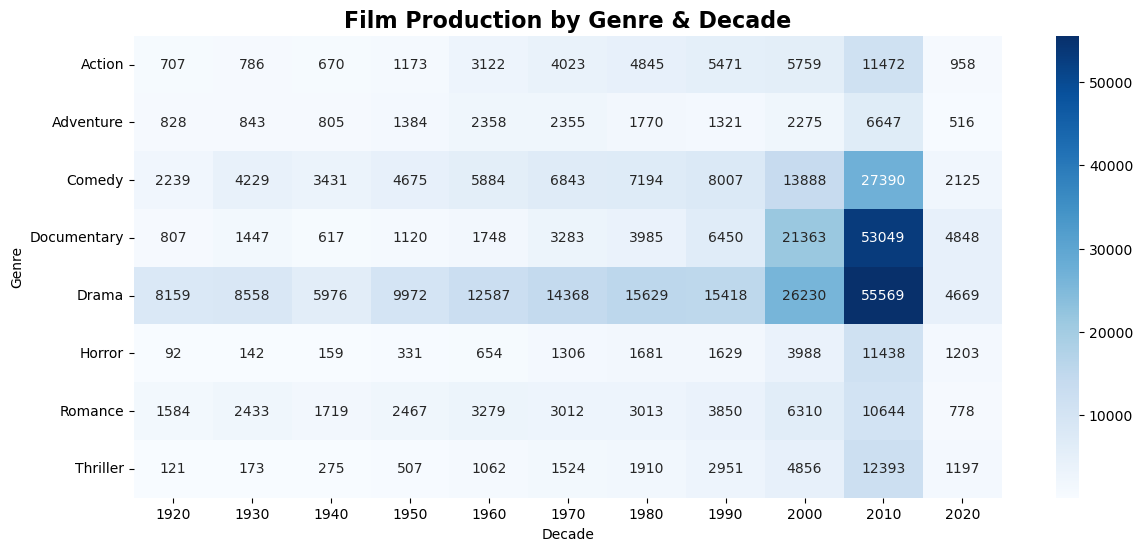

In [11]:
heatmap_data = genre_popularity_heatmap(connection, ['Comedy','Drama','Action', 'Romance', 'Thriller', 'Documentary', 'Horror', 'Adventure'], decade_start = 1920, decade_end = 2020)

**Top Movies with Highest Rate**

In [12]:
def top_movies_of_year(connection, year, min_votes = 5000, top_n = 25):
    sql = """
    WITH year_movies AS (
        SELECT 
            t.title_id,
            t.primary_title,
            t.genres,
            t.premiered,
            t.runtime_minutes,
            r.rating,
            r.votes
        FROM titles AS t
        JOIN ratings r 
        USING(title_id)
        WHERE t.type = 'movie'
          AND t.premiered = :year
          AND r.votes >= :min_votes
          AND t.is_adult = 0
    )
    SELECT *
    FROM year_movies
    ORDER BY rating DESC, votes DESC
    LIMIT :top_n;
    """

    df = pd.read_sql_query(sql, connection, params = {"year": year, "min_votes": min_votes, "top_n": top_n})

# Extract primary genre
    df["main_genre"] = df["genres"].apply(lambda g: g.split(",")[0] if g else "Unknown")
    df_plot = df.sort_values("rating", ascending=True).reset_index(drop = True)

# Visual Settings
    sns.set_theme(style = "white")
    design_colors = [
        "lightsalmon",  
        "khaki",        
        "lightpink",    
        "lightsteelblue",
        "orchid",         
        "rosybrown",    
        "peachpuff",     
        "darkseagreen",
        "lightgrey"]

    unique_genres = df_plot["main_genre"].unique()
    color_map = {g: design_colors[i % len(design_colors)] for i, g in enumerate(unique_genres)}

    bar_colors = df_plot["main_genre"].map(color_map)

# Visualization
    fig, ax = plt.subplots(figsize = (14, 12))
    ax.barh(df_plot["primary_title"], df_plot["rating"], color = bar_colors, edgecolor = "white", linewidth = 1)
    ax.tick_params(axis = 'y', labelsize = 9)

# Label on bars
    for i, row in df_plot.iterrows():
        ax.text(row["rating"] + 0.05, i, f"{row['rating']:.1f} - {row['votes']:,} votes", va = "center", fontsize = 9, color = "black")

# Centered Title
    fig.suptitle(f"Top {top_n} Movies with Highest Rated of {year}", fontsize = 22, fontweight = "bold", y = 0.95)

    ax.set_xlabel("IMDb Rating", fontsize = 12)
    ax.set_ylabel("Movie Title", fontsize = 12)

# Legend 
    handles = [plt.Line2D([0], [0], marker = 'o', linestyle = '', 
                          markerfacecolor = color_map[g], label = g, markersize = 10)
               for g in unique_genres]

    plt.legend(handles = handles, 
               title = "Main Genre", fontsize = 11, title_fontsize = 13,
               loc = "lower right", frameon = True, edgecolor = "black",
               ncol = 2, columnspacing = 1.5,labelspacing = 0.8)

# Center the layout
    plt.subplots_adjust(left = 0.5, right = 0.95, top = 0.88, bottom = 0.05)
    plt.xlim(df_plot["rating"].min() - 0.3, 10)

    sns.despine(left = True, bottom = True)
    plt.tight_layout()
    plt.show()

    return df

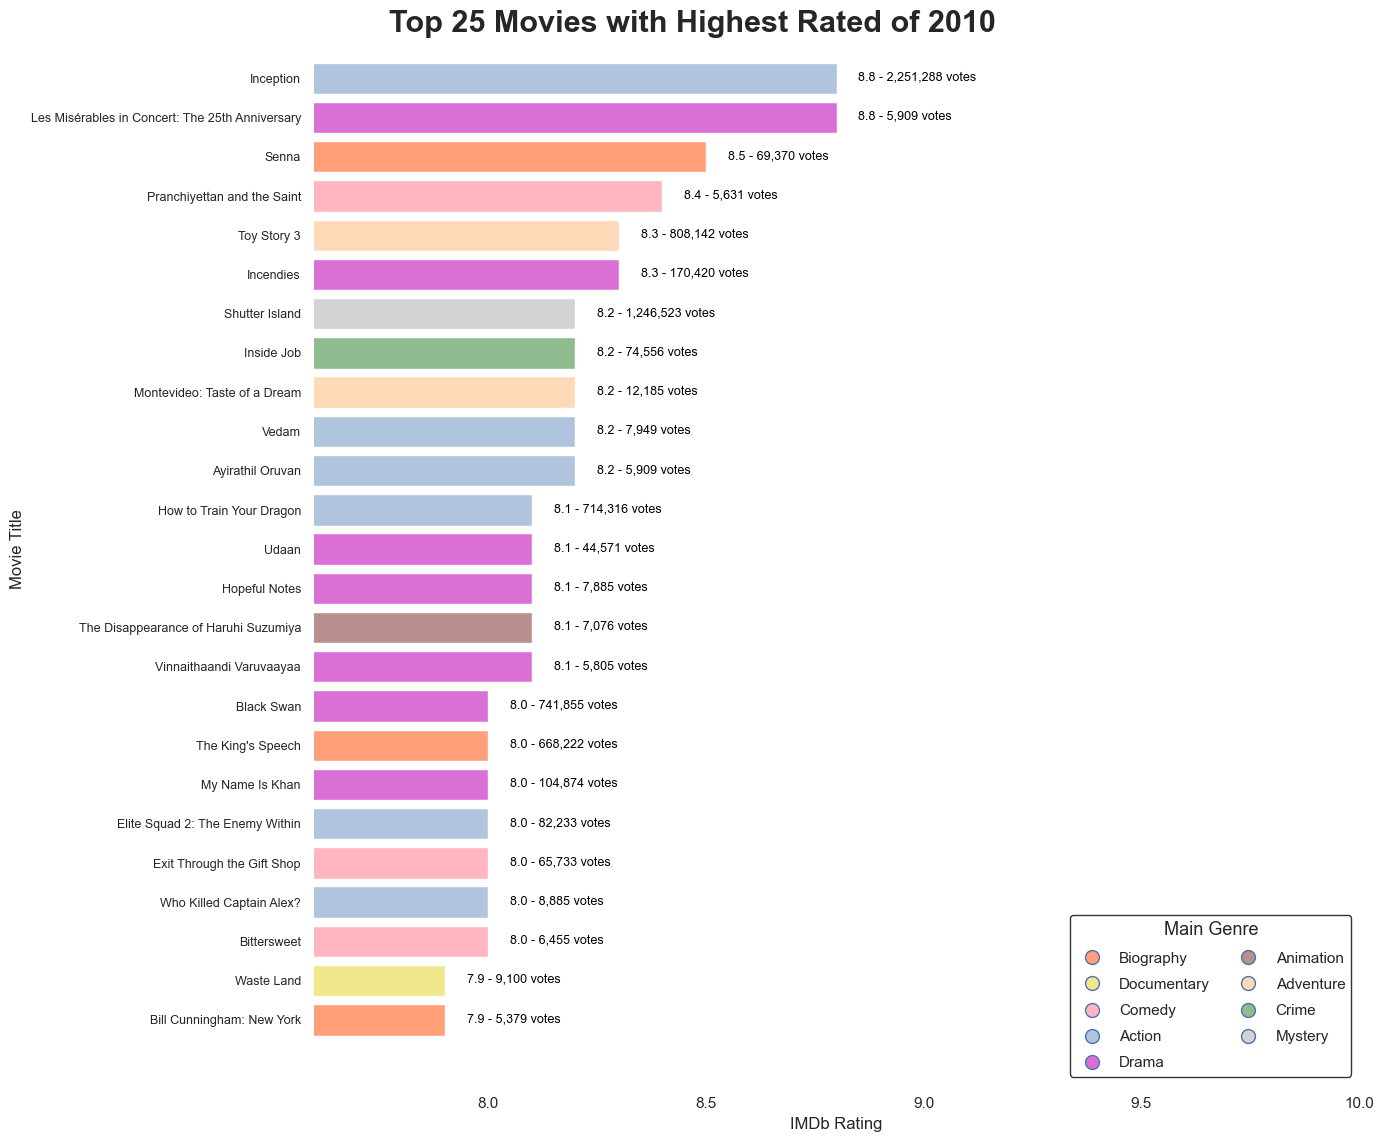

,title_id,primary_title,genres,premiered,runtime_minutes,rating,votes,main_genre
0,tt1375666,Inception,"Action,Adventure,Sci-Fi",2010,148,8.8,2251288,Action
1,tt1754109,Les Misérables in Concert: The 25th Anniversary,"Drama,Music,Musical",2010,178,8.8,5909,Drama
2,tt1424432,Senna,"Biography,Documentary,Sport",2010,106,8.5,69370,Biography
3,tt1695800,Pranchiyettan and the Saint,"Comedy,Drama",2010,140,8.4,5631,Comedy
4,tt0435761,Toy Story 3,"Adventure,Animation,Comedy",2010,103,8.3,808142,Adventure
5,tt1255953,Incendies,"Drama,Mystery,War",2010,131,8.3,170420,Drama
6,tt1130884,Shutter Island,"Mystery,Thriller",2010,138,8.2,1246523,Mystery
7,tt1645089,Inside Job,"Crime,Documentary",2010,109,8.2,74556,Crime
8,tt1634013,Montevideo: Taste of a Dream,"Adventure,Comedy,Drama",2010,140,8.2,12185,Adventure
9,tt1649431,Vedam,"Action,Drama",2010,135,8.2,7949,Action


In [13]:
top_movies_of_year(connection, 2010, min_votes = 5000, top_n = 25)